# RobustRAG — Demo & Research Showcase

## 1. What this demo covers

- Dataset size, label balance, models, and task distribution
- Visual dataset analysis using notebook output cells (plots are **not saved**)
- Example records showing what the model actually sees
- Existing TF-IDF + Logistic Regression baseline
- Baseline configuration and reported metrics
- Confusion matrix and probability/error examples
- Reproducibility checks using the existing project code
- Current status of ablation and robustness experiments


In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run this notebook from the RobustRAG repository root.
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

DATA_PATH = ROOT / 'data' / 'processed' / 'ragtruth.jsonl'
CONFIG_PATH = ROOT / 'configs' / 'default.yaml'
ARTIFACT_DIR = ROOT / 'reports' / 'experiments' / 'baseline_tfidf_logreg'

print('Repository:', ROOT)
print('Dataset exists:', DATA_PATH.exists())
print('Baseline artifact directory exists:', ARTIFACT_DIR.exists())

Repository: c:\Users\nishantwhat\CODE\RobustRAG
Dataset exists: True
Baseline artifact directory exists: True


In [4]:
from hallucination_detector.data.loader import load_jsonl

records = load_jsonl(DATA_PATH)
df = pd.DataFrame(records)

print(f'Records: {len(df):,}')
print(f'Columns: {list(df.columns)}')
df.head(10)

Records: 17,790
Columns: ['id', 'source_id', 'question', 'context', 'answer', 'hallucinated', 'model', 'temperature', 'split', 'quality', 'annotations']


,id,source_id,question,context,answer,hallucinated,model,temperature,split,quality,annotations
0,6,15593,Summarize the following news within 89 words:\...,"Andrew Getty, one of the heirs to billions of ...","Andrew Getty, oil tycoon J. Paul Getty's grand...",False,gpt-4-0613,0.7,train,good,[]
1,7,15593,Summarize the following news within 89 words:\...,"Andrew Getty, one of the heirs to billions of ...","Andrew Getty, one of the heirs to billions of ...",False,gpt-3.5-turbo-0613,0.7,train,good,[]
2,8,15593,Summarize the following news within 89 words:\...,"Andrew Getty, one of the heirs to billions of ...","Andrew Getty, one of the heirs to billions of ...",False,mistral-7B-instruct,0.7,train,good,[]
3,9,15593,Summarize the following news within 89 words:\...,"Andrew Getty, one of the heirs to billions of ...","Andrew Getty, a billionaire heir to the Getty ...",False,llama-2-7b-chat,0.7,train,good,[]
4,10,15593,Summarize the following news within 89 words:\...,"Andrew Getty, one of the heirs to billions of ...","Andrew Getty, an heir to the Getty oil fortune...",True,llama-2-13b-chat,0.7,train,good,"[{'start': 280, 'end': 327, 'text': 'His net w..."
5,11,15593,Summarize the following news within 89 words:\...,"Andrew Getty, one of the heirs to billions of ...","Andrew Getty, an heir to the Getty oil fortune...",False,llama-2-70b-chat,0.7,train,good,[]
6,12,15594,Summarize the following news within 98 words:\...,"Since Iran's Islamic Revolution in 1979, women...",Iran is set to lift its ban on women attending...,False,gpt-4-0613,0.7,train,good,[]
7,13,15594,Summarize the following news within 98 words:\...,"Since Iran's Islamic Revolution in 1979, women...",The ban on women attending sports events in Ir...,False,gpt-3.5-turbo-0613,0.7,train,good,[]
8,14,15594,Summarize the following news within 98 words:\...,"Since Iran's Islamic Revolution in 1979, women...",Iran is planning to lift its ban on women atte...,False,mistral-7B-instruct,0.7,train,good,[]
9,15,15594,Summarize the following news within 98 words:\...,"Since Iran's Islamic Revolution in 1979, women...",In an effort to improve Iran's chances of host...,False,llama-2-7b-chat,0.7,train,good,[]


## 2. Dataset snapshot

These values are computed directly from the processed dataset already used by the project.

In [5]:
summary = pd.DataFrame({
    'Measure': [
        'Total records', 'Train records', 'Test records',
        'Supported', 'Hallucinated', 'Hallucination rate',
        'Unique sources', 'Unique models'
    ],
    'Value': [
        len(df),
        int((df['split'] == 'train').sum()),
        int((df['split'] == 'test').sum()),
        int((df['hallucinated'] == False).sum()),
        int((df['hallucinated'] == True).sum()),
        f"{df['hallucinated'].mean():.2%}",
        df['source_id'].nunique(),
        df['model'].nunique(),
    ]
})
display(summary)

,Measure,Value
0,Total records,17790
1,Train records,13578
2,Test records,2700
3,Supported,10126
4,Hallucinated,7664
5,Hallucination rate,43.08%
6,Unique sources,2965
7,Unique models,6


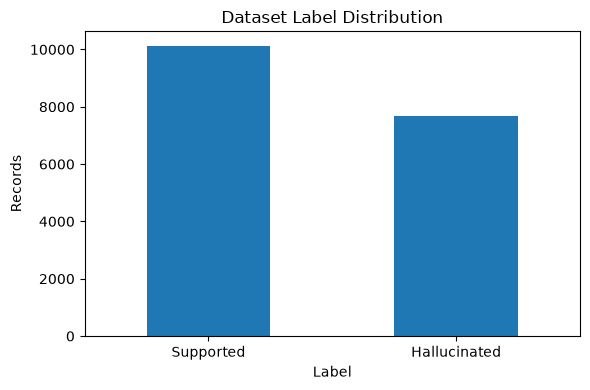

In [6]:
# Dataset label balance — displayed directly in the notebook output.
label_counts = df['hallucinated'].map({False: 'Supported', True: 'Hallucinated'}).value_counts()

plt.figure(figsize=(6, 4))
label_counts.plot(kind='bar')
plt.title('Dataset Label Distribution')
plt.xlabel('Label')
plt.ylabel('Records')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

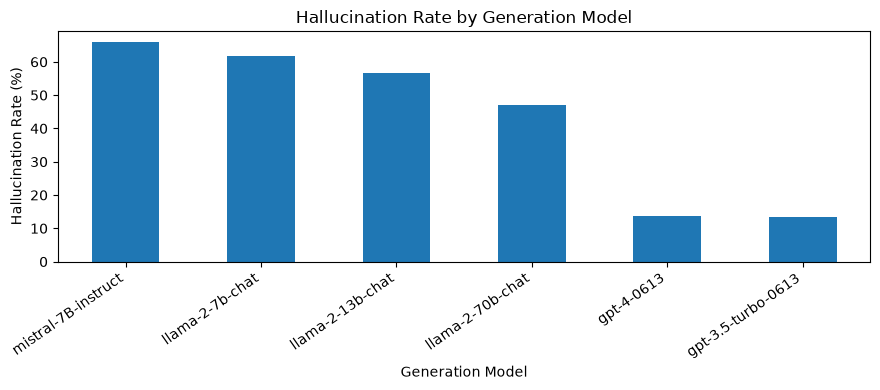

,hallucination_rate_%
model,
mistral-7B-instruct,65.87
llama-2-7b-chat,61.79
llama-2-13b-chat,56.56
llama-2-70b-chat,47.05
gpt-4-0613,13.69
gpt-3.5-turbo-0613,13.52


In [7]:
# Model-level hallucination rates — descriptive dataset analysis only.
model_rates = (
    df.groupby('model')['hallucinated']
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 4))
model_rates.mul(100).plot(kind='bar')
plt.title('Hallucination Rate by Generation Model')
plt.xlabel('Generation Model')
plt.ylabel('Hallucination Rate (%)')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

display(model_rates.mul(100).round(2).rename('hallucination_rate_%').to_frame())

,mean,median
Supported,118.79,111.0
Hallucinated,146.23,138.0


<Figure size 800x400 with 0 Axes>

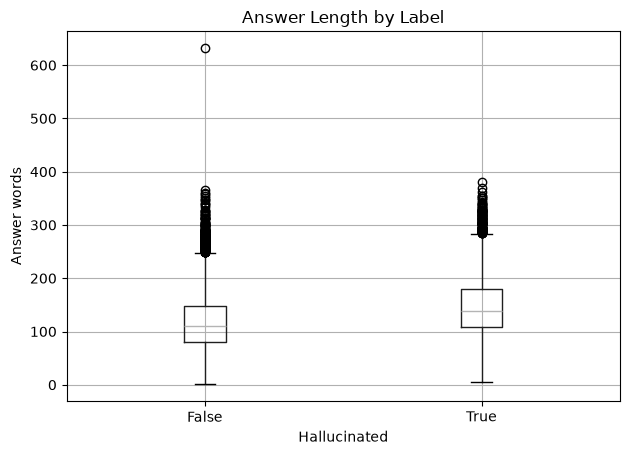

In [8]:
# Answer length by label — reproduces the existing descriptive analysis using the processed data.
df['answer_words_demo'] = df['answer'].astype(str).str.split().str.len()
length_summary = df.groupby('hallucinated')['answer_words_demo'].agg(['mean', 'median'])
length_summary.index = ['Supported', 'Hallucinated']
display(length_summary.round(2))

plt.figure(figsize=(8, 4))
df.boxplot(column='answer_words_demo', by='hallucinated')
plt.title('Answer Length by Label')
plt.suptitle('')
plt.xlabel('Hallucinated')
plt.ylabel('Answer words')
plt.tight_layout()
plt.show()

## 3. What does one example look like?

The baseline is deliberately text-grounded: it uses the **context + answer** rather than IDs, annotations, or other metadata. The examples below make that distinction visible.

In [9]:
example_cols = ['id', 'model', 'hallucinated', 'question', 'context', 'answer']

for label, title in [(False, 'Supported example'), (True, 'Hallucinated example')]:
    row = df[df['hallucinated'] == label].iloc[0]
    print(f'\n===== {title} =====')
    print('Question:', row['question'])
    print('Context:', row['context'])
    print('Answer:', row['answer'])
    print('Label:', 'Hallucinated' if row['hallucinated'] else 'Supported')


===== Supported example =====
Question: Summarize the following news within 89 words:
Andrew Getty, one of the heirs to billions of oil money, appears to have died of natural causes, a Los Angeles Police Department spokesman said. The coroner's preliminary assessment is there was no foul play involved in the death of Getty, grandson of oil tycoon J. Paul Getty, said Detective Meghan Aguilar. Andrew Getty, 47, had "several health issues," Aguilar said, adding that an autopsy will be conducted. There is no criminal investigation underway, he said. Some medication had also been recovered from Getty's home, though investigators don't know whether Getty was taking it or what his medical history was, Ed Winter, assistant chief in the Los Angeles County coroner's office, told CNN affiliate KTLA Tuesday night. KTLA reported that Getty was found on his side near a bathroom in his home. Getty's parents, Ann and Gordon Getty, released a statement confirming their son's death and asking for priva

## 4. Existing baseline

Pipeline already implemented in the project:

**Context + Answer → TF-IDF (1–2 grams) → Logistic Regression → Hallucination probability**

The notebook does not reimplement this pipeline. It imports the existing classifier and reads the saved experiment outputs.

In [10]:
import yaml

with CONFIG_PATH.open('r', encoding='utf-8') as f:
    config = yaml.safe_load(f)

display(pd.DataFrame([
    ['Input mode', config['baseline']['input_mode']],
    ['N-gram range', str(config['baseline']['ngram_range'])],
    ['min_df', config['baseline']['min_df']],
    ['max_df', config['baseline']['max_df']],
    ['sublinear_tf', config['baseline']['sublinear_tf']],
    ['C', config['baseline']['C']],
    ['max_iter', config['baseline']['max_iter']],
], columns=['Setting', 'Value']))

,Setting,Value
0,Input mode,ca
1,N-gram range,"[1, 2]"
2,min_df,2
3,max_df,0.95
4,sublinear_tf,True
5,C,1.0
6,max_iter,1000


In [11]:
# Prefer the saved baseline metrics produced by the existing training script.
metrics_candidates = [
    ARTIFACT_DIR / 'metrics.json',
    ARTIFACT_DIR / 'metrics.jsonl',
]

metrics_path = next((p for p in metrics_candidates if p.exists()), None)
if metrics_path is None:
    print('Saved metrics file not found. Run the existing baseline training script first:')
    print('uv run python scripts/train_baseline.py')
else:
    if metrics_path.suffix == '.json':
        metrics = json.loads(metrics_path.read_text(encoding='utf-8'))
    else:
        metrics = json.loads(metrics_path.read_text(encoding='utf-8').splitlines()[0])
    display(pd.DataFrame([metrics]))

,accuracy,precision,recall,f1,roc_auc,average_precision,confusion_matrix,classification_report,test_records,positive_rate
0,0.767778,0.690361,0.607635,0.646362,0.797654,0.733342,"[[1500, 257], [370, 573]]",{'supported': {'precision': 0.8021390374331551...,2700,0.349259


In [12]:
# The reported baseline result, shown as a presentation-friendly table.
# These are the project's existing reported test-set results.
baseline_results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'Average Precision'],
    'Score': [0.7678, 0.6904, 0.6076, 0.6464, 0.7977, 0.7333]
})
baseline_results['Score'] = baseline_results['Score'].map(lambda x: f'{x:.4f}')
display(baseline_results)

,Metric,Score
0,Accuracy,0.7678
1,Precision,0.6904
2,Recall,0.6076
3,F1,0.6464
4,ROC-AUC,0.7977
5,Average Precision,0.7333


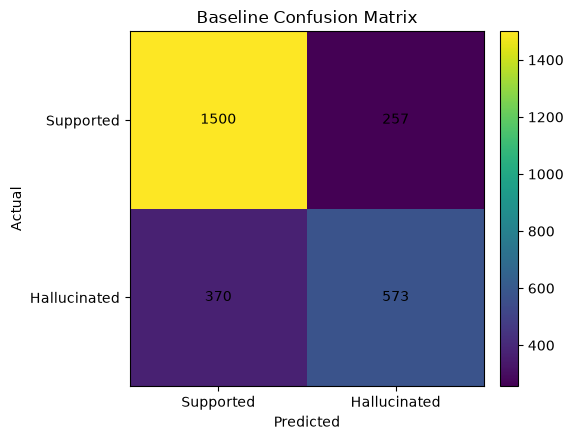

In [13]:
# Existing baseline confusion matrix.
cm = np.array([[1500, 257], [370, 573]])

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm)
ax.set_xticks([0, 1], ['Supported', 'Hallucinated'])
ax.set_yticks([0, 1], ['Supported', 'Hallucinated'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Baseline Confusion Matrix')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### How to explain the result

On the 2,700-record test set, the classical text-only baseline reaches **76.78% accuracy, 69.04% precision, 60.76% recall, and 64.64% F1** for the hallucinated class. Its **ROC-AUC of 0.7977** and **Average Precision of 0.7333** show that context + answer text contains meaningful signal for distinguishing hallucinated from supported responses. The confusion matrix also makes the limitation clear: **370 hallucinated answers are missed**, while **257 supported answers are incorrectly flagged**. This makes the model a useful reference point for stronger models and later robustness experiments rather than a final detector.

## 5. Example: what a user would see

A showcase should demonstrate the detector as a system, not only as a score table. The following cell uses the project's existing inference component when the saved model artifact is available.

In [18]:
model_path = ARTIFACT_DIR / 'model.pkl'

if model_path.exists():
    from hallucination_detector.inference.baseline import load_baseline

    demo_model = load_baseline(model_path)
    demo_rows = df[df['split'] == 'test'].head(3)
    demo_predictions = demo_model.predict_proba(demo_rows.to_dict('records'))
    demo_view = pd.DataFrame({
        'Actual': demo_rows['hallucinated'].map({False: 'Supported', True: 'Hallucinated'}).to_numpy(),
        'P(Hallucinated)': demo_predictions[:, 1],
    })
    demo_view['Prediction'] = np.where(demo_view['P(Hallucinated)'] >= 0.5, 'Hallucinated', 'Supported')
    display(demo_view)
else:
    print('Saved model artifact not found. The showcase can still display the reported evaluation results.')

AttributeError: 'dict' object has no attribute 'context'

## 6. Error examples

For a presentation, false positives and false negatives are often more informative than another metric. If the saved test predictions are available, inspect representative errors here rather than creating a second evaluation implementation.

In [16]:
prediction_candidates = [
    ARTIFACT_DIR / 'test_predictions.csv',
    ARTIFACT_DIR / 'predictions.csv',
]
prediction_path = next((p for p in prediction_candidates if p.exists()), None)

if prediction_path is None:
    print('Saved test predictions were not found. No new error-analysis logic is introduced here.')
else:
    pred = pd.read_csv(prediction_path)
    print('Prediction artifact columns:', list(pred.columns))
    display(pred.head())

Saved test predictions were not found. No new error-analysis logic is introduced here.


## 7. Ablation & robustness — current research status

These are important next experiments, but this showcase notebook **does not fabricate results or implement a second experimental pipeline**.

### Ablation

The natural controlled comparison is to keep the classifier fixed and vary the information supplied to it, for example:

- Answer only
- Context + Answer (current baseline)
- Question + Answer
- Question + Context + Answer

If those experiments have already been run by the project, their saved result tables can be displayed here. If not, they belong in the experiment/training stage rather than being silently added to this demo.

### Robustness

The project already has source-aware structure in its data. A later robustness study can examine whether performance remains stable when evaluation is grouped by source/model/task or under controlled distribution shifts. Again, this notebook should only display completed experiments; it should not manufacture a robustness claim from the current baseline alone.

## 8. Research takeaway

The current evidence establishes a clean classical reference point: **surface-level and context-conditioned textual signals are already informative for hallucination detection, but they are insufficient to reliably catch all hallucinations**. The next research value comes from understanding *why* the baseline fails and whether additional representations, stronger language models, controlled ablations, and robustness evaluations improve generalization without introducing leakage.

## 9. Reproducibility

From the repository root:

```bash
uv run pytest -q
uv run python scripts/train_baseline.py
```

Then open this notebook. The notebook is intended for **presentation and inspection**, while training and experiment logic remain in the project's existing Python modules and scripts.